# BlinkIT Grocery Sales Analysis
**Domain:** Retail & Grocery Sales Analytics  
**Organization context:** Sapphire IQ  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

## Project purpose
Analyze grocery sales across products, categories, outlet types, outlet sizes, and outlet locations. The work follows the four objectives in the provided project guide:
1. Understand business and sales performance.
2. Check whether the available information is reliable.
3. Identify factors associated with stronger sales performance.
4. Provide practical recommendations for management.

> This notebook uses the supplied `BlinkIT Grocery Data.xlsx` file. Findings describe the supplied dataset and should not be interpreted as proof of causation.


## 1. Import libraries and load the data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Place BlinkIT Grocery Data.xlsx in the same folder as this notebook.
file_path = Path("/content/BlinkIT Grocery Data (1).xlsx")
df = pd.read_excel(file_path)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0



Column names:
['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Item Weight', 'Sales', 'Rating']


## 2. Understand the business and sales performance

In [4]:
print("Rows and columns:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("Data type"))
print("\nNumeric summary:")
display(df.describe().T)
print("\nUnique values in key categorical columns:")
for col in ["Item Fat Content", "Item Type", "Outlet Location Type", "Outlet Size", "Outlet Type"]:
    print(f"\n{col}:")
    display(df[col].value_counts(dropna=False).to_frame("Count"))

Rows and columns: (8523, 12)

Data types:


,Data type
Item Fat Content,object
Item Identifier,object
Item Type,object
Outlet Establishment Year,int64
Outlet Identifier,object
Outlet Location Type,object
Outlet Size,object
Outlet Type,object
Item Visibility,float64
Item Weight,float64



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Outlet Establishment Year,8523.0,2016.450546,3.189396,2011.000,2014.000000,2016.000000,2018.000000,2022.000000
Item Visibility,8523.0,0.066132,0.051598,0.000,0.026989,0.053931,0.094585,0.328391
Item Weight,7060.0,12.857645,4.643456,4.555,8.773750,12.600000,16.850000,21.350000
Sales,8523.0,140.992783,62.275067,31.290,93.826500,143.012800,185.643700,266.888400
Rating,8523.0,3.965857,0.605651,1.000,4.000000,4.000000,4.200000,5.000000



Unique values in key categorical columns:

Item Fat Content:


...

,Count
Outlet Location Type,
Tier 3,3350
Tier 2,2785
Tier 1,2388



Outlet Size:


,Count
Outlet Size,
Medium,3631
Small,3139
High,1753



Outlet Type:


,Count
Outlet Type,
Supermarket Type1,5577
Grocery Store,1083
Supermarket Type3,935
Supermarket Type2,928


## 3. Data quality checks

In [5]:
# Missing values
missing = df.isna().sum().to_frame("Missing values")
missing["Missing %"] = (missing["Missing values"] / len(df) * 100).round(2)
display(missing)

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check inconsistent labels in Item Fat Content
display(df["Item Fat Content"].value_counts(dropna=False).to_frame("Count"))

# Check ranges for numeric fields
display(df[["Outlet Establishment Year", "Item Visibility", "Item Weight", "Sales", "Rating"]].describe().T)

,Missing values,Missing %
Item Fat Content,0,0.00
Item Identifier,0,0.00
Item Type,0,0.00
Outlet Establishment Year,0,0.00
Outlet Identifier,0,0.00
Outlet Location Type,0,0.00
Outlet Size,0,0.00
Outlet Type,0,0.00
Item Visibility,0,0.00
Item Weight,1463,17.17


Duplicate rows: 0


,Count
Item Fat Content,
Low Fat,5089
Regular,2889
LF,316
reg,117
low fat,112


,count,mean,std,min,25%,50%,75%,max
Outlet Establishment Year,8523.0,2016.450546,3.189396,2011.000,2014.000000,2016.000000,2018.000000,2022.000000
Item Visibility,8523.0,0.066132,0.051598,0.000,0.026989,0.053931,0.094585,0.328391
Item Weight,7060.0,12.857645,4.643456,4.555,8.773750,12.600000,16.850000,21.350000
Sales,8523.0,140.992783,62.275067,31.290,93.826500,143.012800,185.643700,266.888400
Rating,8523.0,3.965857,0.605651,1.000,4.000000,4.000000,4.200000,5.000000


### Cleaning decisions
- Standardize `LF` and `low fat` to `Low Fat`, and `reg` to `Regular`.
- Fill missing `Item Weight` values with the median weight for the same `Item Type`; if a type has no usable median, use the overall median.
- No duplicate rows were found in the supplied dataset.
- The original data is preserved in `df`; cleaning is applied to a separate copy called `clean_df`.


In [6]:
clean_df = df.copy()

clean_df["Item Fat Content"] = clean_df["Item Fat Content"].replace({
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular"
})

missing_weight_before = clean_df["Item Weight"].isna().sum()
type_medians = clean_df.groupby("Item Type")["Item Weight"].transform("median")
clean_df["Item Weight"] = clean_df["Item Weight"].fillna(type_medians)
clean_df["Item Weight"] = clean_df["Item Weight"].fillna(clean_df["Item Weight"].median())

print("Missing item weights before cleaning:", missing_weight_before)
print("Missing item weights after cleaning:", clean_df["Item Weight"].isna().sum())
print("\nStandardized fat content values:")
display(clean_df["Item Fat Content"].value_counts().to_frame("Count"))
print("\nRemaining missing values:")
display(clean_df.isna().sum().to_frame("Missing values"))

Missing item weights before cleaning: 1463
Missing item weights after cleaning: 0

Standardized fat content values:


,Count
Item Fat Content,
Low Fat,5517
Regular,3006



Remaining missing values:


,Missing values
Item Fat Content,0
Item Identifier,0
Item Type,0
Outlet Establishment Year,0
Outlet Identifier,0
Outlet Location Type,0
Outlet Size,0
Outlet Type,0
Item Visibility,0
Item Weight,0


## 4. Key performance indicators (KPIs)

In [7]:
total_sales = clean_df["Sales"].sum()
average_sales_per_record = clean_df["Sales"].mean()
median_sales_per_record = clean_df["Sales"].median()
average_rating = clean_df["Rating"].mean()
total_records = len(clean_df)
unique_items = clean_df["Item Identifier"].nunique()
unique_outlets = clean_df["Outlet Identifier"].nunique()

kpis = pd.DataFrame({
    "Metric": ["Total sales", "Average sales per record", "Median sales per record",
               "Average customer rating", "Number of records", "Unique item identifiers",
               "Number of outlets"],
    "Value": [total_sales, average_sales_per_record, median_sales_per_record,
              average_rating, total_records, unique_items, unique_outlets]
})
display(kpis.round(2))

,Metric,Value
0,Total sales,1201681.49
1,Average sales per record,140.99
2,Median sales per record,143.01
3,Average customer rating,3.97
4,Number of records,8523.00
5,Unique item identifiers,1559.00
6,Number of outlets,10.00


## 5. Sales by product category

,Records,Total_Sales,Average_Sales,Average_Rating
Item Type,,,,
Fruits and Vegetables,1232,178124.08,144.58,3.96
Snack Foods,1200,175433.92,146.19,3.95
Household,910,135976.53,149.42,4.00
Frozen Foods,856,118558.88,138.50,3.97
Dairy,682,101276.46,148.50,3.97
Canned,649,90706.73,139.76,3.99
Baking Goods,648,81894.74,126.38,3.98
Health and Hygiene,520,68025.84,130.82,3.99
Meat,425,59449.86,139.88,4.02


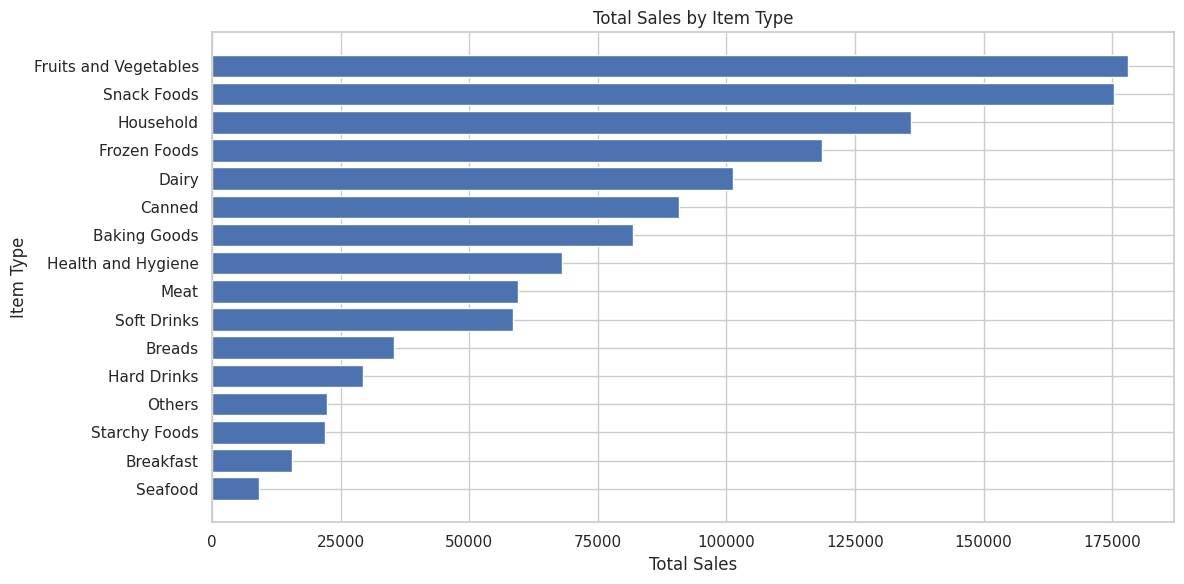

In [8]:
category_sales = (clean_df.groupby("Item Type")
                 .agg(Records=("Sales", "size"),
                      Total_Sales=("Sales", "sum"),
                      Average_Sales=("Sales", "mean"),
                      Average_Rating=("Rating", "mean"))
                 .sort_values("Total_Sales", ascending=False))
display(category_sales.round(2))

plot_data = category_sales.sort_values("Total_Sales")
plt.figure(figsize=(12, 6))
plt.barh(plot_data.index, plot_data["Total_Sales"])
plt.title("Total Sales by Item Type")
plt.xlabel("Total Sales")
plt.ylabel("Item Type")
plt.tight_layout()
plt.show()

## 6. Sales by outlet type and location

,Records,Total_Sales,Average_Sales,Average_Rating
Outlet Type,,,,
Supermarket Type1,5577,787549.89,141.21,3.96
Grocery Store,1083,151939.15,140.29,3.99
Supermarket Type2,928,131477.78,141.68,3.97
Supermarket Type3,935,130714.67,139.80,3.95


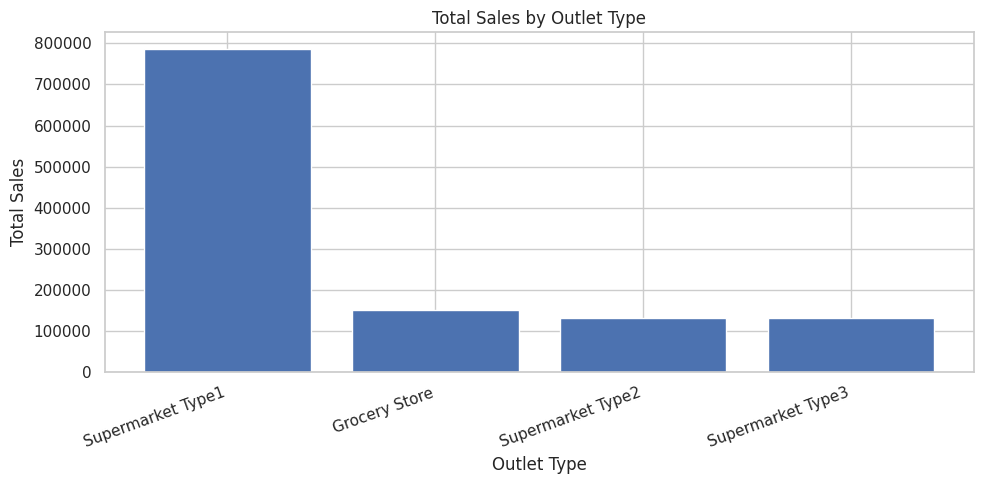

,Records,Total_Sales,Average_Sales,Average_Rating
Outlet Location Type,,,,
Tier 3,3350,472133.03,140.94,3.96
Tier 2,2785,393150.65,141.17,3.96
Tier 1,2388,336397.81,140.87,3.98


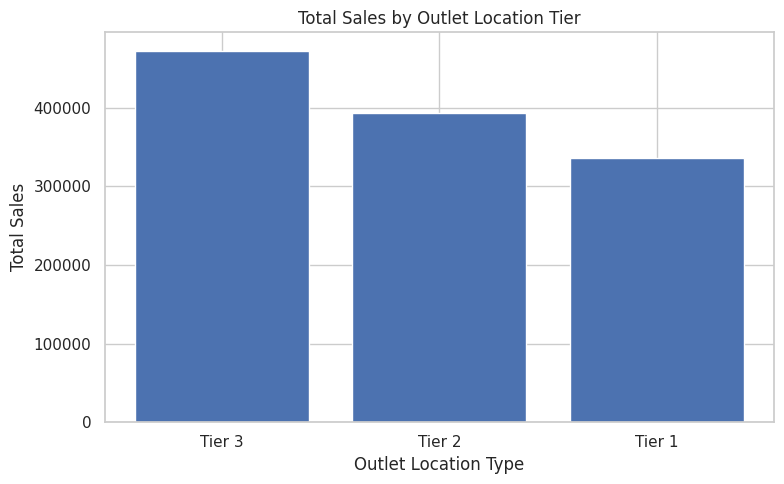

In [9]:
outlet_type_sales = (clean_df.groupby("Outlet Type")
                    .agg(Records=("Sales", "size"),
                         Total_Sales=("Sales", "sum"),
                         Average_Sales=("Sales", "mean"),
                         Average_Rating=("Rating", "mean"))
                    .sort_values("Total_Sales", ascending=False))
display(outlet_type_sales.round(2))

plt.figure(figsize=(10, 5))
plt.bar(outlet_type_sales.index, outlet_type_sales["Total_Sales"])
plt.title("Total Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

location_sales = (clean_df.groupby("Outlet Location Type")
                  .agg(Records=("Sales", "size"),
                       Total_Sales=("Sales", "sum"),
                       Average_Sales=("Sales", "mean"),
                       Average_Rating=("Rating", "mean"))
                  .sort_values("Total_Sales", ascending=False))
display(location_sales.round(2))

plt.figure(figsize=(8, 5))
plt.bar(location_sales.index, location_sales["Total_Sales"])
plt.title("Total Sales by Outlet Location Tier")
plt.xlabel("Outlet Location Type")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

## 7. Sales by outlet size and fat content

,Records,Total_Sales,Average_Sales
Outlet Size,,,
Medium,3631,507895.74,139.88
Small,3139,444794.17,141.70
High,1753,248991.59,142.04


,Records,Total_Sales,Average_Sales
Item Fat Content,,,
Low Fat,5517,776319.69,140.71
Regular,3006,425361.80,141.50


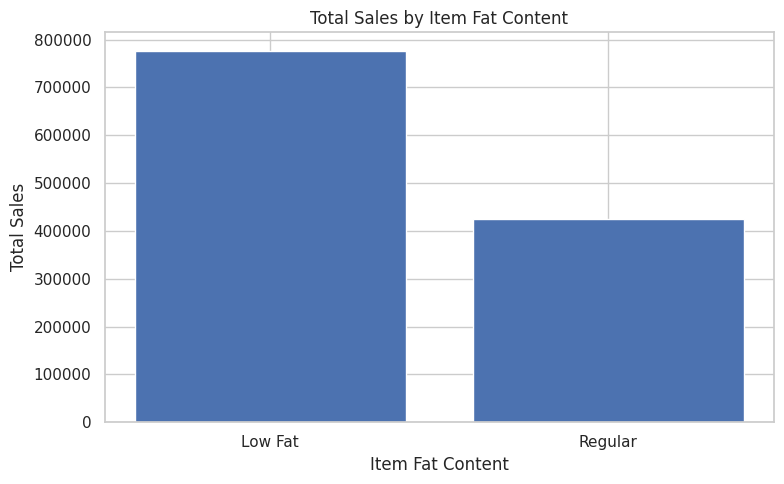

In [10]:
outlet_size_sales = (clean_df.groupby("Outlet Size")
                    .agg(Records=("Sales", "size"),
                         Total_Sales=("Sales", "sum"),
                         Average_Sales=("Sales", "mean"))
                    .sort_values("Total_Sales", ascending=False))
display(outlet_size_sales.round(2))

fat_sales = (clean_df.groupby("Item Fat Content")
             .agg(Records=("Sales", "size"),
                  Total_Sales=("Sales", "sum"),
                  Average_Sales=("Sales", "mean"))
             .sort_values("Total_Sales", ascending=False))
display(fat_sales.round(2))

plt.figure(figsize=(8, 5))
plt.bar(fat_sales.index, fat_sales["Total_Sales"])
plt.title("Total Sales by Item Fat Content")
plt.xlabel("Item Fat Content")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

## 8. Relationships between numeric variables

,Item Visibility,Item Weight,Sales,Rating
Item Visibility,1.000,-0.013,-0.001,0.001
Item Weight,-0.013,1.000,0.027,0.004
Sales,-0.001,0.027,1.000,0.011
Rating,0.001,0.004,0.011,1.000


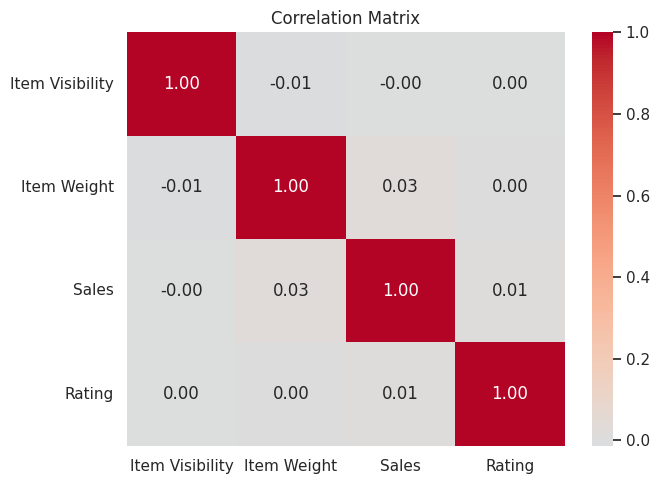

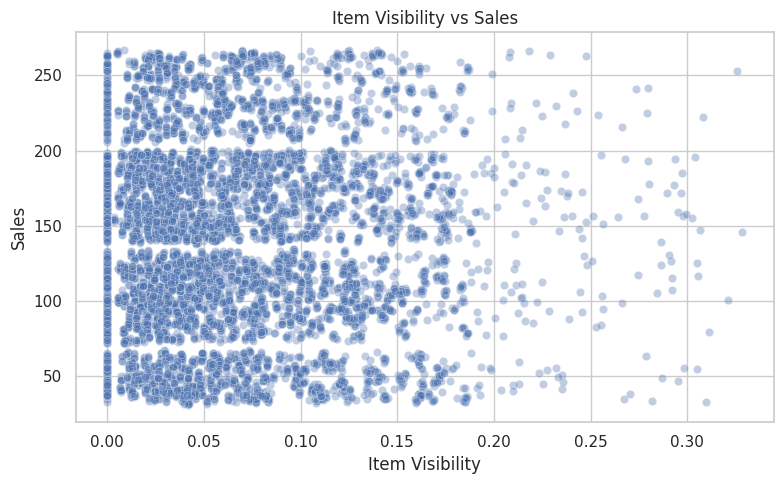

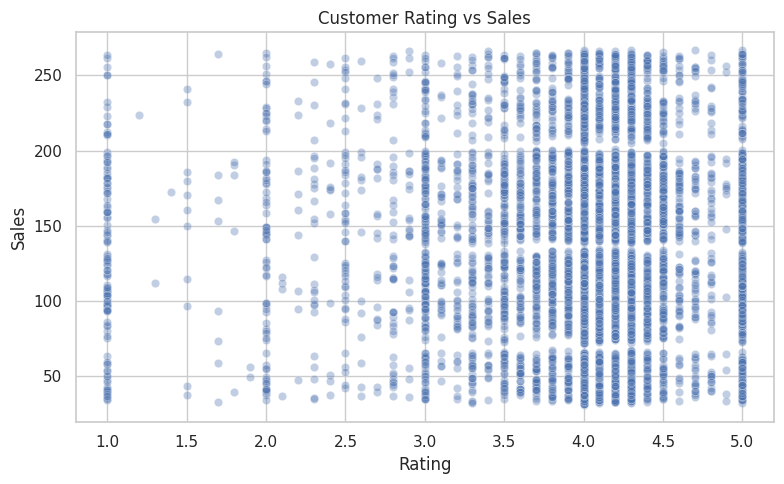

In [ ]:
numeric_cols = ["Item Visibility", "Item Weight", "Sales", "Rating"]
corr = clean_df[numeric_cols].corr(numeric_only=True)
display(corr.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=clean_df, x="Item Visibility", y="Sales", alpha=0.35)
plt.title("Item Visibility vs Sales")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=clean_df, x="Rating", y="Sales", alpha=0.35)
plt.title("Customer Rating vs Sales")
plt.tight_layout()
plt.show()

## 9. Key findings generated from the supplied dataset

In [11]:
top_category = category_sales["Total_Sales"].idxmax()
top_category_value = category_sales.loc[top_category, "Total_Sales"]
top_outlet_type = outlet_type_sales["Total_Sales"].idxmax()
top_outlet_value = outlet_type_sales.loc[top_outlet_type, "Total_Sales"]
top_location = location_sales["Total_Sales"].idxmax()
top_location_value = location_sales.loc[top_location, "Total_Sales"]
missing_weight_count = df["Item Weight"].isna().sum()
fat_labels = clean_df["Item Fat Content"].value_counts()

print(f"1. Total sales across all {len(clean_df):,} records: {total_sales:,.2f}.")
print(f"2. Highest total sales by item type: {top_category} ({top_category_value:,.2f}).")
print(f"3. Highest total sales by outlet type: {top_outlet_type} ({top_outlet_value:,.2f}).")
print(f"4. Highest total sales by location tier: {top_location} ({top_location_value:,.2f}).")
print(f"5. Average rating: {average_rating:.2f} out of 5.")
print(f"6. Missing item weights found before cleaning: {missing_weight_count:,}.")
print("7. The original fat-content labels included inconsistent spellings/abbreviations; these were standardized.")
print("8. Category and outlet totals are influenced by how many records belong to each group, so compare both totals and average sales.")

1. Total sales across all 8,523 records: 1,201,681.49.
2. Highest total sales by item type: Fruits and Vegetables (178,124.08).
3. Highest total sales by outlet type: Supermarket Type1 (787,549.89).
4. Highest total sales by location tier: Tier 3 (472,133.03).
5. Average rating: 3.97 out of 5.
6. Missing item weights found before cleaning: 1,463.
7. The original fat-content labels included inconsistent spellings/abbreviations; these were standardized.
8. Category and outlet totals are influenced by how many records belong to each group, so compare both totals and average sales.


## 10. Business recommendations
1. **Protect strong categories:** Review inventory availability and promotion plans for categories with high total sales, especially Fruits and Vegetables and Snack Foods in this dataset.
2. **Use outlet comparisons carefully:** Supermarket Type1 contributes the largest total sales, but it also has the most records. Compare average sales and record counts before deciding that one outlet type is inherently better.
3. **Investigate location opportunities:** Tier 3 has the largest total sales in this dataset. Review assortment, stock availability, and demand patterns by outlet before reallocating resources.
4. **Improve data quality at entry:** Ensure item weight is captured consistently and fat-content labels use a controlled list.
5. **Use customer ratings as a monitoring measure:** Average ratings are around four out of five. Examine lower-rated items individually before changing assortment or promotions.
6. **Test changes before scaling:** Run small, measurable tests on promotions or product placement and compare results over time.

## 11. Limitations
- The dataset does not include dates for individual sales records, so a true daily/monthly sales trend cannot be derived from this file alone.
- The dataset contains sales values but no cost or profit field; profitability cannot be calculated reliably.
- The data is observational. Relationships and group differences do not prove that one factor causes higher sales.
- Missing item weights were imputed for analysis; imputed values are estimates, not original observations.

## 12. Export the cleaned dataset
Run this cell to save a cleaned CSV in the notebook's working directory.


In [12]:
clean_df.to_csv("BlinkIT_Cleaned_Data.csv", index=False)
print("Saved: BlinkIT_Cleaned_Data.csv")

Saved: BlinkIT_Cleaned_Data.csv
